Two-mode network reduction with the island method (Batagelj & Zaversnik).

Usage:
    python movielens_islands.py out.movielens-100k_rating [u.item]

Steps: load bipartite ratings -> keep "liked" ties -> project each mode ->
find islands (threshold sweep, components within a size range) -> reduce the
bipartite graph to island members -> profile each island from the other mode.

In [1]:
import argparse
import os
import numpy as np
import pandas as pd
# import matplotlib
# matplotlib.use("Agg")
import matplotlib.pyplot as plt
import networkx as nx
from scipy import sparse
from scipy.sparse.csgraph import connected_components

In [2]:
def project(A):
    """One-mode projection; edge weight = number of shared neighbours."""
    W = (A @ A.T).tocsr()
    W.setdiag(0)
    W.eliminate_zeros()
    return W

In [3]:
def find_islands(W, min_size=3, max_size=30, n_thresh=150):
    """Maximal connected components of {edges >= t} whose size is in range.
    Every edge leaving such a component is < t <= every edge inside its
    spanning tree, so each is an island in Batagelj's sense.
    Also returns the threshold sweep (t, #in-range components) for plotting."""
    ts = np.unique(np.quantile(W.data, np.linspace(0, 0.9995, n_thresh)))
    kept, sweep = [], []
    for t in ts:                      # ascending: larger islands found first
        M = W.copy()
        M.data[M.data < t] = 0
        M.eliminate_zeros()
        _, lab = connected_components(M, directed=False)
        sizes = np.bincount(lab)
        ok = np.where((sizes >= min_size) & (sizes <= max_size))[0]
        sweep.append((t, len(ok)))
        for c in ok:
            members = frozenset(np.where(lab == c)[0].tolist())
            if not any(members <= k for k in kept):
                kept.append(members)
    return [sorted(k) for k in kept], np.array(sweep)

In [4]:
def profile(A_side, islands, labels, top=5):
    base = np.asarray(A_side.mean(axis=0)).ravel()
    rows = []
    for i, members in enumerate(islands):
        share = np.asarray(A_side[members].mean(axis=0)).ravel()
        best = np.argsort(-(share - base))[:top]
        rows.append((i, len(members), [(labels[j], round(share[j], 2), round(base[j], 2)) for j in best]))
    return rows

def save(fig, outdir, name):
    fig.tight_layout()
    fig.savefig(os.path.join(outdir, name), dpi=150)
    plt.close(fig)
    print("  saved", name)

In [5]:
def save(fig, outdir, name, preview=True):
    fig.tight_layout()
    if preview:
        plt.show(block=False)      # open the window without blocking the script
        plt.pause(0.5)             # give it time to draw
        if input(f"Save {name}? [y/n] ").strip().lower() != "y":
            plt.close(fig)
            return
    fig.savefig(os.path.join(outdir, name), dpi=150)
    plt.close(fig)
    print("  saved", name)

In [40]:
def plot_degrees(A, outdir):
    fig, ax = plt.subplots(1, 2, figsize=(10, 4))
    for a, deg, lab in [(ax[0], np.asarray(A.sum(axis=1)).ravel(), "movies liked per user"),
                        (ax[1], np.asarray(A.sum(axis=0)).ravel(), "users who liked each movie")]:
        a.hist(deg, bins=40, color="#4C72B0")
        a.set_yscale("log")
        a.set_xlabel(lab); a.set_ylabel("count (log)")
        a.set_title(f"median {np.median(deg):.0f}, max {deg.max():.0f}")
    fig.suptitle("1. Degree distributions of the 'liked' network")
    save(fig, outdir, "1_degree_distributions.png")

In [41]:
def plot_reduction(before, after, outdir):
    fig, ax = plt.subplots(1, 3, figsize=(10, 3.8))
    for a, name, b, f in zip(ax, ["Users", "Movies", "Ties"], before, after):
        bars = a.bar(["before", "after"], [b, f], color=["#999999", "#C44E52"])
        a.set_title(name)
        a.bar_label(bars, labels=[f"{b:,}", f"{f:,} ({f / b:.0%})"])
        a.set_ylim(0, b * 1.15)
    fig.suptitle("2. Reduction by the island method")

In [42]:
def plot_island_sizes(U_isl, M_isl, outdir):
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
    for a, isl, name in [(ax[0], U_isl, "User islands"), (ax[1], M_isl, "Movie islands")]:
        a.hist([len(g) for g in isl], bins=range(2, 32), color="#55A868")
        a.set_title(f"{name} (n={len(isl)})"); a.set_xlabel("island size")
    ax[0].set_ylabel("number of islands")
    fig.suptitle("3. Island size distributions")
    save(fig, outdir, "3_island_sizes.png")

In [43]:
def plot_sweep(sw_u, sw_m, outdir):
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
    for a, sw, name in [(ax[0], sw_u, "User projection"), (ax[1], sw_m, "Movie projection")]:
        a.plot(sw[:, 0], sw[:, 1], color="#8172B2")
        a.set_title(name); a.set_xlabel("weight threshold (shared neighbours)")
        a.set_ylabel("components within size range")
    fig.suptitle("4. Threshold sweep")
    save(fig, outdir, "4_threshold_sweep.png")

In [44]:
def plot_network(sub, u_island, m_island, outdir):
    """Reduced bipartite graph. Circles = users, squares = movies,
    colour = island."""
    G = nx.Graph()
    ui, mi = sub.nonzero()
    G.add_nodes_from([("u", i) for i in range(sub.shape[0])])
    G.add_nodes_from([("m", j) for j in range(sub.shape[1])])
    G.add_edges_from((("u", a), ("m", b)) for a, b in zip(ui, mi))
    pos = nx.spring_layout(G, seed=1, k=0.6 / np.sqrt(max(len(G), 1)), iterations=200)
    cmap = plt.get_cmap("tab20")
    fig, ax = plt.subplots(figsize=(9, 8))
    nx.draw_networkx_edges(G, pos, alpha=0.08, width=0.5, ax=ax)
    for kind, shape, isl in [("u", "o", u_island), ("m", "s", m_island)]:
        nodes = [n for n in G if n[0] == kind]
        nx.draw_networkx_nodes(G, pos, nodelist=nodes, node_shape=shape, node_size=28,
                               node_color=[cmap(isl[n[1]] % 20) for n in nodes],
                               edgecolors="black", linewidths=0.3, ax=ax)
    ax.plot([], [], "ko", label="user"); ax.plot([], [], "ks", label="movie")
    ax.legend(loc="upper right"); ax.axis("off")
    ax.set_title("5. Reduced bipartite network (colour = island)")
    save(fig, outdir, "5_reduced_network.png")

In [45]:
def plot_heatmap(A, U_isl, M_isl, outdir):
    """Cell = average share of the movie island's movies liked by members of
    the user island."""
    Ad = A.tocsr()
    H = np.zeros((len(U_isl), len(M_isl)))
    for i, ug in enumerate(U_isl):
        rows = Ad[ug]
        for j, mg in enumerate(M_isl):
            H[i, j] = rows[:, mg].mean()
    fig, ax = plt.subplots(figsize=(max(6, 0.35 * len(M_isl) + 3), max(4, 0.3 * len(U_isl) + 2)))
    im = ax.imshow(H, cmap="viridis", aspect="auto")
    ax.set_xlabel("movie island"); ax.set_ylabel("user island")
    ax.set_xticks(range(len(M_isl))); ax.set_yticks(range(len(U_isl)))
    ax.tick_params(labelsize=7)
    fig.colorbar(im, label="share of movie island liked by user island")
    ax.set_title("6. Duality: user islands x movie islands")
    save(fig, outdir, "6_duality_heatmap.png")
    pd.DataFrame(H).to_csv(os.path.join(outdir, "duality_matrix.csv"))

In [46]:
def plot_genres(G, M_isl, outdir):
    sel = sorted(range(len(M_isl)), key=lambda i: -len(M_isl[i]))[:MAX_SHOWN]
    shares = np.array([G[M_isl[i]].sum(axis=0) for i in sel], dtype=float)
    shares = shares / np.maximum(shares.sum(axis=1, keepdims=True), 1)
    cmap = plt.get_cmap("tab20")
    fig, ax = plt.subplots(figsize=(11, 5))
    bottom = np.zeros(len(sel))
    for g in range(len(GENRES)):
        ax.bar([f"M{i}" for i in sel], shares[:, g], bottom=bottom, color=cmap(g % 20), label=GENRES[g])
        bottom += shares[:, g]
    ax.set_ylabel("share of genre tags"); ax.set_xlabel("movie island")
    ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=7)
    ax.set_title("7. Genre profile of movie islands")
    save(fig, outdir, "7_genre_profile.png")

In [47]:
def plot_demographics(meta, U_isl, outdir):
    sel = sorted(range(len(U_isl)), key=lambda i: -len(U_isl[i]))[:MAX_SHOWN]
    age, sex, occ = meta.age.values, meta.gender.values, meta.occupation.values
    labels = [f"U{i}" for i in sel]
    top_occ = pd.Series(occ).value_counts().index[:10]
    O = np.array([[np.mean(occ[U_isl[i]] == o) for o in top_occ] for i in sel])
    fig, ax = plt.subplots(1, 3, figsize=(16, 5), gridspec_kw={"width_ratios": [1, 1, 1.2]})
    ax[0].boxplot([age[U_isl[i]] for i in sel])
    ax[0].set_xticklabels(labels)
    ax[0].axhline(np.nanmedian(age), color="red", ls="--", label="all users (median)")
    ax[0].set_ylabel("age"); ax[0].legend(fontsize=7); ax[0].set_title("Age")
    ax[1].bar(labels, [np.mean(sex[U_isl[i]] == "F") for i in sel], color="#DD8452")
    ax[1].axhline(np.mean(sex == "F"), color="red", ls="--", label="all users")
    ax[1].set_ylabel("share female"); ax[1].legend(fontsize=7); ax[1].set_title("Gender")
    im = ax[2].imshow(O, cmap="magma_r", aspect="auto")
    ax[2].set_xticks(range(len(top_occ))); ax[2].set_xticklabels(top_occ, rotation=60, ha="right", fontsize=7)
    ax[2].set_yticks(range(len(sel))); ax[2].set_yticklabels(labels, fontsize=7)
    fig.colorbar(im, ax=ax[2], label="share of island"); ax[2].set_title("Occupation")
    for a in ax[:2]:
        a.tick_params(axis="x", labelrotation=90, labelsize=7)
    fig.suptitle("8. Demographic profile of user islands")
    save(fig, outdir, "8_demographic_profile.png")

In [8]:
GENRES = ["unknown", "Action", "Adventure", "Animation", "Children's", "Comedy",
          "Crime", "Documentary", "Drama", "Fantasy", "Film-Noir", "Horror",
          "Musical", "Mystery", "Romance", "Sci-Fi", "Thriller", "War", "Western"]
MAX_SHOWN = 25          # cap islands shown in profile graphs (largest first)

In [39]:
ap = argparse.ArgumentParser()
ap.add_argument("ratings")
ap.add_argument("items", nargs="?")
ap.add_argument("users_meta", nargs="?")
ap.add_argument("--outdir", default="/Users/Audiorunner13/CUNY MSDS Course Work/Data620 Fall 2026/Week 6/Project 2/results")
ap.add_argument("--min-size", type=int, default=3)
ap.add_argument("--max-size", type=int, default=30)
ap.add_argument("--min-rating", type=int, default=4)

a = ap.parse_args([
    "ratings.csv",            # ratings (required positional)
    "items.csv",              # items (optional)
    "users_meta.csv",         # users_meta (optional)
    "--outdir", "results",
    "--min-size", "2",
    "--max-size", "200",
    "--min-rating", "4",
])
os.makedirs(a.outdir, exist_ok=True)

In [10]:
data_path='/Users/Audiorunner13/CUNY MSDS Course Work/Data620 Fall 2026/Week 6/Project 2/ml-100k/u.data'
min_rating=4

item_path=None

In [11]:
df = pd.read_csv(data_path, sep=r"\s+", comment="%", header=None).iloc[:, :3]
df.columns = ["user", "movie", "rating"]
n_raw = len(df)
df = df[df.rating >= min_rating].drop_duplicates(["user", "movie"])
print(f"Ratings: {n_raw:,} -> {len(df):,} after keeping rating >= {min_rating}")
users, u_idx = np.unique(df.user, return_inverse=True)
movies, m_idx = np.unique(df.movie, return_inverse=True)
A = sparse.csr_matrix((np.ones(len(df)), (u_idx, m_idx)),
                          shape=(len(users), len(movies)))
#    return A, users, movies

Ratings: 100,000 -> 55,375 after keeping rating >= 4


In [12]:
print(f"Bipartite network: {A.shape[0]:,} users, {A.shape[1]:,} movies, {A.nnz:,} ties")

Bipartite network: 942 users, 1,447 movies, 55,375 ties


In [13]:
titles, G = movies.astype(str), None

In [14]:
item_path='/Users/Audiorunner13/CUNY MSDS Course Work/Data620 Fall 2026/Week 6/Project 2/ml-100k/u.item'
if a.items:
    meta = pd.read_csv(item_path, sep="|", header=None, encoding="latin-1").set_index(0)
    titles = np.array([meta[1].get(m, str(m)) for m in movies])
    G = meta.reindex(movies).iloc[:, 4:23].fillna(0).values.astype(float)

In [15]:
user_path='/Users/Audiorunner13/CUNY MSDS Course Work/Data620 Fall 2026/Week 6/Project 2/ml-100k/u.user'
umeta = None
if a.users_meta:
    umeta = pd.read_csv(user_path, names=["id", "age", "gender", "occupation", "zip"]).set_index("id").reindex(users)

In [16]:
U_isl, sw_u = find_islands(project(A), a.min_size, a.max_size)
M_isl, sw_m = find_islands(project(A.T.tocsr()), a.min_size, a.max_size)
print(f"\nUser islands: {len(U_isl)}   Movie islands: {len(M_isl)}")
if not U_isl or not M_isl:
    print("No islands found: try a larger --max-size or smaller --min-size.")


User islands: 2   Movie islands: 1


In [17]:
print(A.shape, A.nnz)
print(project(A).shape, project(A).nnz)

(942, 1447) 55375
(942, 942) 764884


In [18]:
u_keep = sorted({u for g in U_isl for u in g})
m_keep = sorted({m for g in M_isl for m in g})
sub = A[u_keep][:, m_keep]
print("\nREDUCTION")
print(f"  users : {A.shape[0]:,} -> {len(u_keep):,}")
print(f"  movies: {A.shape[1]:,} -> {len(m_keep):,}")
print(f"  ties  : {A.nnz:,} -> {sub.nnz:,}")


REDUCTION
  users : 942 -> 53
  movies: 1,447 -> 194
  ties  : 55,375 -> 5,238


In [19]:
print("\nUSER ISLANDS: movies their members like far more than average")
for i, n, top in profile(A, U_isl, titles)[:10]:
    print(f"  island {i} (n={n}):", "; ".join(f"{t} [{s} vs {b}]" for t, s, b in top))
print("\nMOVIE ISLANDS: how concentrated is their audience?")

for i, members in enumerate(M_isl[:10]):
    aud = np.asarray(A[:, members].sum(axis=1)).ravel()
    print(f"  island {i} (n={len(members)}): {', '.join(titles[members][:5])} "
            f"| users liking >=half: {int((aud >= max(2, 0.5 * len(members))).sum())}")
 
# membership tables
rows = [("user", i, users[u]) for i, g in enumerate(U_isl) for u in g]
rows += [("movie", i, titles[m]) for i, g in enumerate(M_isl) for m in g]
pd.DataFrame(rows, columns=["mode", "island", "node"]).to_csv(
    os.path.join(a.outdir, "island_members.csv"), index=False)


USER ISLANDS: movies their members like far more than average
  island 0 (n=2): Indian Summer (1996) [1.0 vs 0.01]; Spawn (1997) [1.0 vs 0.03]; Lost Highway (1997) [1.0 vs 0.06]; Everyone Says I Love You (1996) [1.0 vs 0.08]; Gattaca (1997) [1.0 vs 0.08]
  island 1 (n=51): Shawshank Redemption, The (1994) [0.9 vs 0.27]; Jaws (1975) [0.82 vs 0.2]; Unforgiven (1992) [0.76 vs 0.14]; Forrest Gump (1994) [0.86 vs 0.24]; Back to the Future (1985) [0.84 vs 0.25]

MOVIE ISLANDS: how concentrated is their audience?
  island 0 (n=194): Toy Story (1995), Get Shorty (1995), Twelve Monkeys (1995), Babe (1995), Dead Man Walking (1995) | users liking >=half: 34



GRAPHS


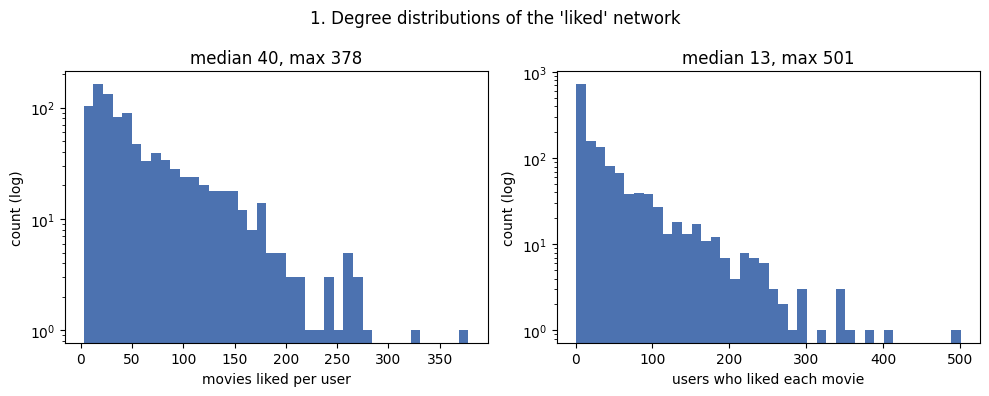

Save 1_degree_distributions.png? [y/n]  y


  saved 1_degree_distributions.png


In [48]:
print("\nGRAPHS")
plot_degrees(A, a.outdir)

# plot_reduction((A.shape[0], A.shape[1], A.nnz), (len(u_keep), len(m_keep), sub.nnz), a.outdir)

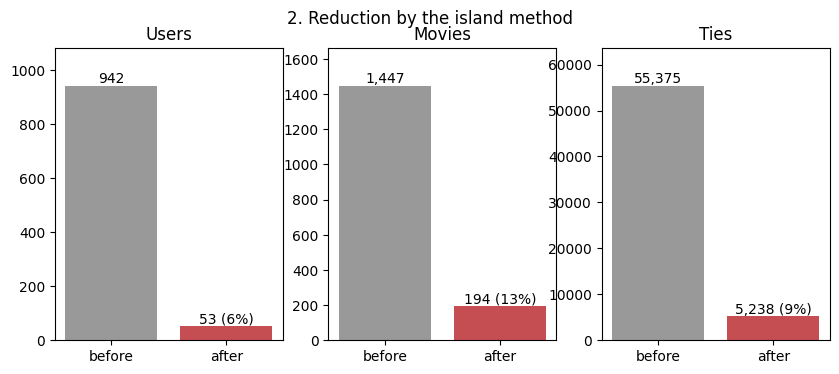

In [49]:
plot_reduction((A.shape[0], A.shape[1], A.nnz), (len(u_keep), len(m_keep), sub.nnz), a.outdir)

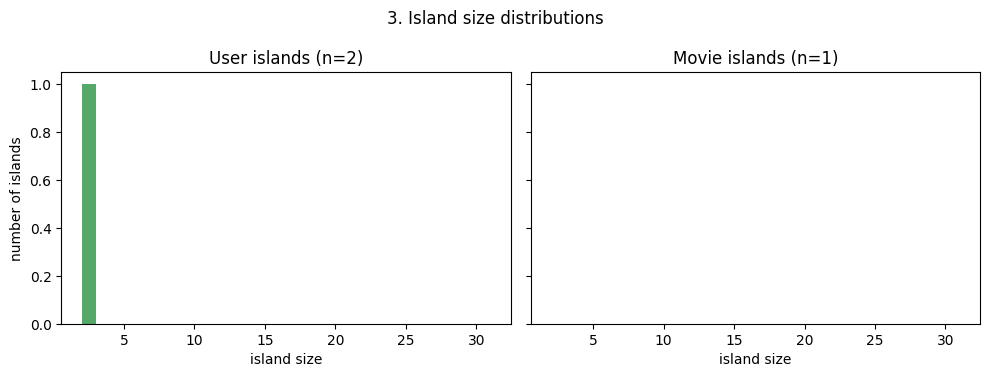

Save 3_island_sizes.png? [y/n]  y


  saved 3_island_sizes.png


In [50]:
plot_island_sizes(U_isl, M_isl, a.outdir)

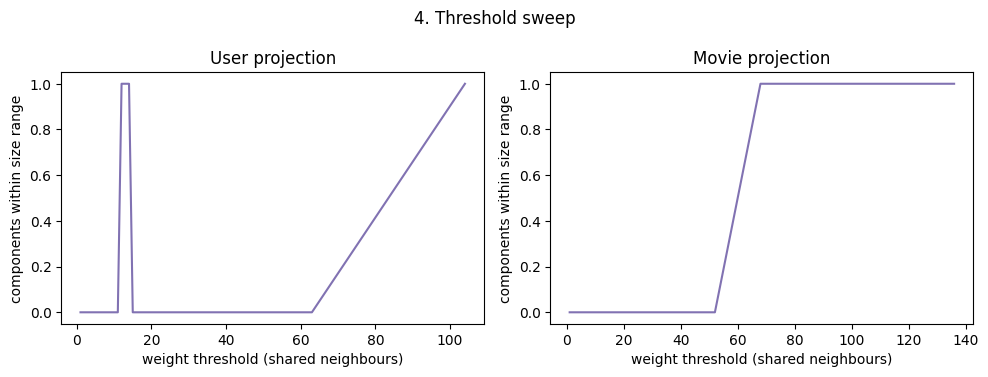

Save 4_threshold_sweep.png? [y/n]  y


  saved 4_threshold_sweep.png


In [51]:
plot_sweep(sw_u, sw_m, a.outdir)

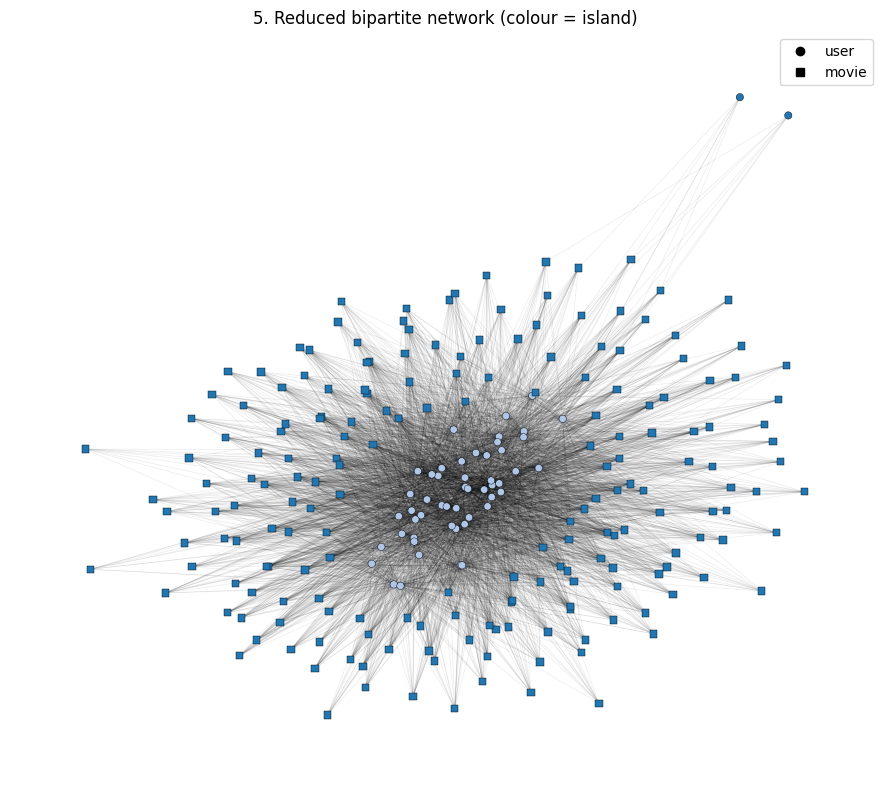

Save 5_reduced_network.png? [y/n]  y


  saved 5_reduced_network.png


In [52]:
m_lab = {m_keep.index(m): i for i, g in enumerate(M_isl) for m in g}
u_lab = {u_keep.index(u): i for i, g in enumerate(U_isl) for u in g}
plot_network(sub, u_lab, m_lab, a.outdir)

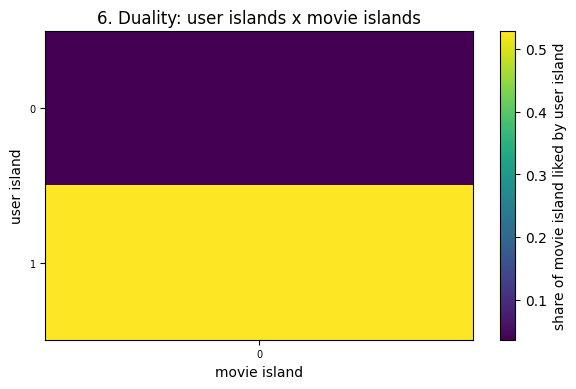

Save 6_duality_heatmap.png? [y/n]  y


  saved 6_duality_heatmap.png


In [53]:
plot_heatmap(A, U_isl, M_isl, a.outdir)

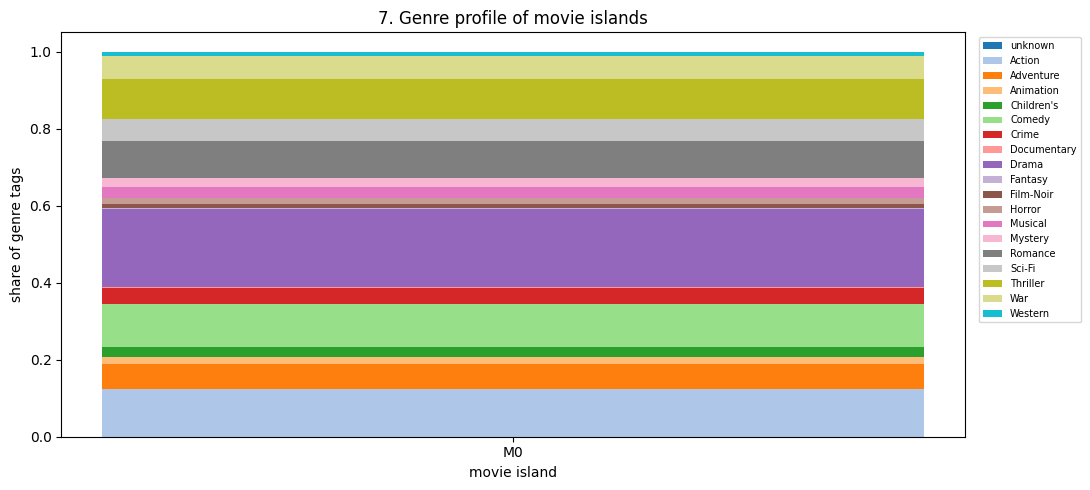

Save 7_genre_profile.png? [y/n]  y


  saved 7_genre_profile.png


/var/folders/zn/8ww5yfhx2f177yrzh1p8zh700000gn/T/ipykernel_46305/468429623.py:10: RuntimeWarning: All-NaN slice encountered
  ax[0].axhline(np.nanmedian(age), color="red", ls="--", label="all users (median)")
/var/folders/zn/8ww5yfhx2f177yrzh1p8zh700000gn/T/ipykernel_46305/468429623.py:15: UserWarning: Attempting to set identical low and high xlims makes transformation singular; automatically expanding.
  im = ax[2].imshow(O, cmap="magma_r", aspect="auto")


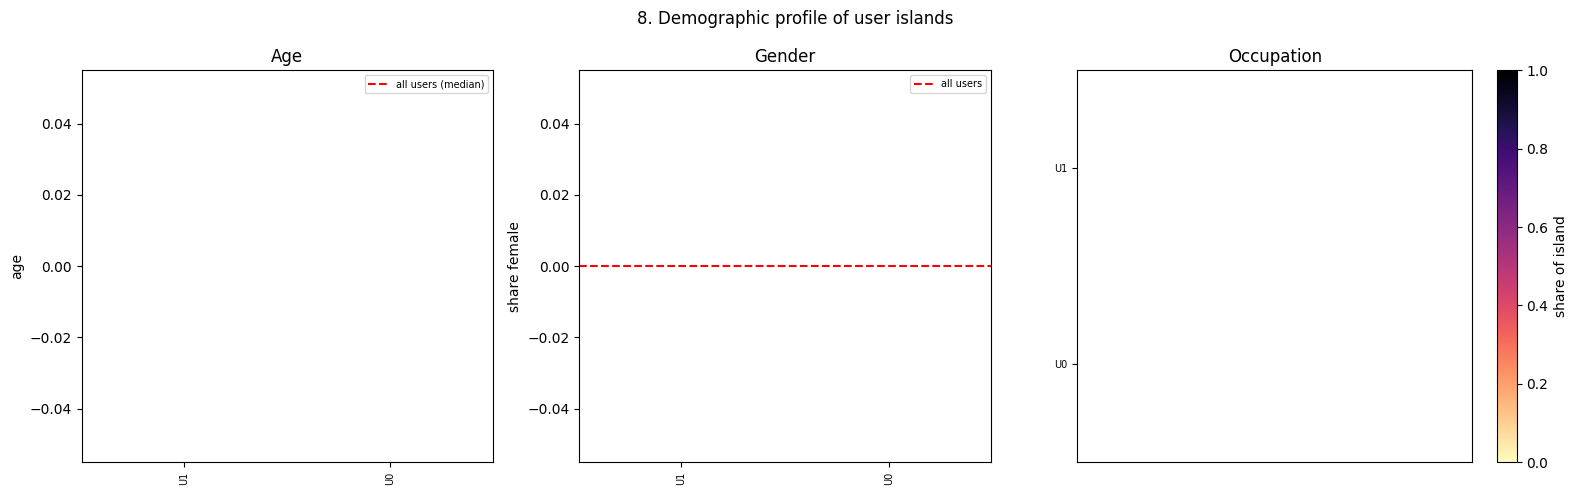

Save 8_demographic_profile.png? [y/n]  y


  saved 8_demographic_profile.png

All outputs in ./results/


In [54]:
if G is not None:
    plot_genres(G, M_isl, a.outdir)
else:
    print("  (skipping genre graph: pass u.item)")

if umeta is not None:
    plot_demographics(umeta, U_isl, a.outdir)
else:
    print("  (skipping demographic graph: pass u.user)")
print(f"\nAll outputs in ./{a.outdir}/")